In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import linkage, dendrogram

In [2]:
df = pd.read_csv("hierarchical_customers.csv")

print("Shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())


Shape: (600, 8)

Missing values:
customer_id             0
income                 41
spending_score         33
purchase_frequency     35
average_order_value    45
website_engagement     33
loyalty_years          28
age                    45
dtype: int64


In [3]:
X = df.drop(columns=["customer_id"])

In [4]:
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X)


In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)


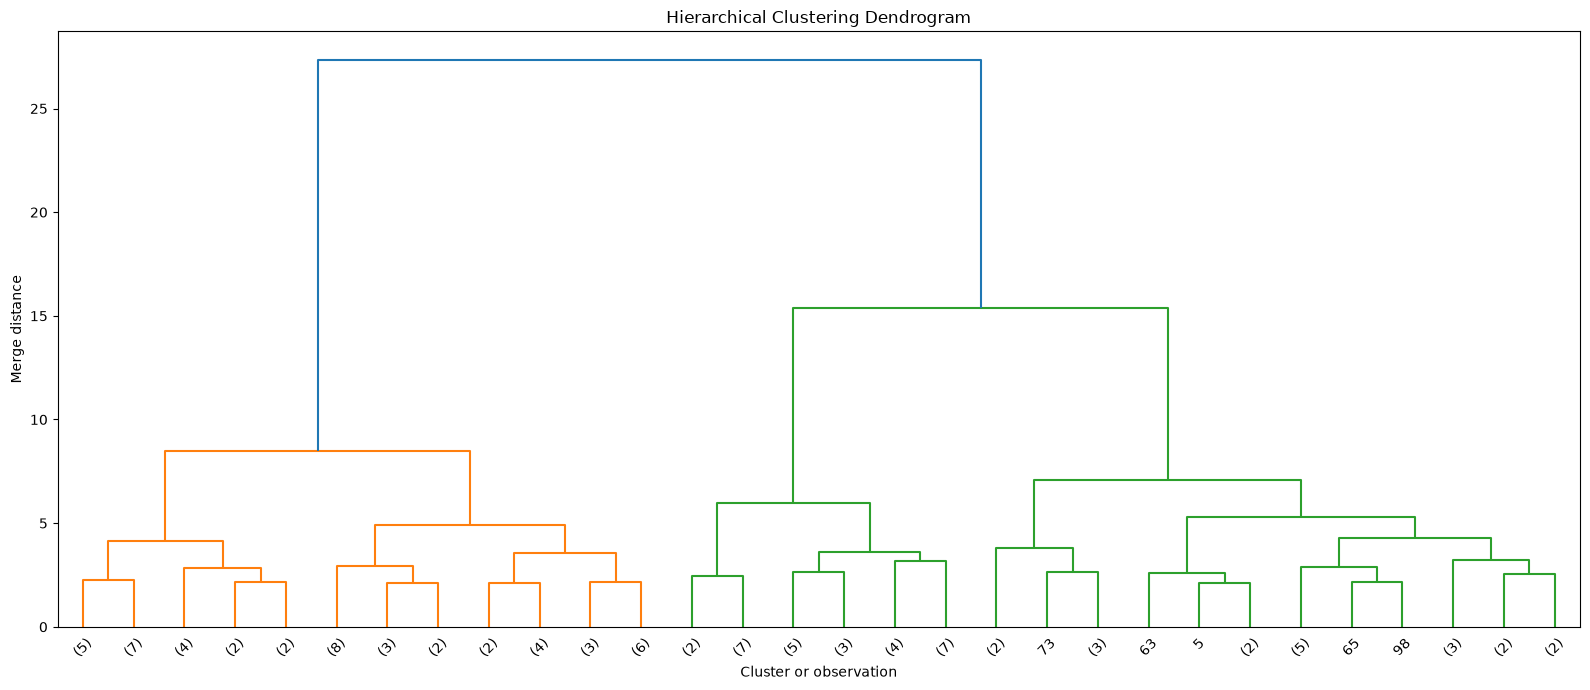

In [6]:
rng = np.random.RandomState(42)
sample_indices = rng.choice(
    len(X_scaled), size=100, replace=False
)
X_sample = X_scaled[sample_indices]

Z = linkage(X_sample, method="ward")

plt.figure(figsize=(16, 7))
dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True
)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Cluster or observation")
plt.ylabel("Merge distance")
plt.tight_layout()
plt.show()


In [7]:
model = AgglomerativeClustering(
    n_clusters=4,
    linkage="ward"
)

labels = model.fit_predict(X_scaled)

df["cluster"] = labels

print("\nCluster sizes:")
print(df["cluster"].value_counts().sort_index())



Cluster sizes:
cluster
0    204
1    125
2    210
3     61
Name: count, dtype: int64


In [8]:
score = silhouette_score(
    X_scaled, labels, sample_size=1000,
    random_state=42
)

print("\nSilhouette score:", round(score, 4))



Silhouette score: 0.2944


In [9]:
print("\nCluster profiles:")
print(
    df.groupby("cluster")[X.columns]
      .mean()
      .round(2)
)


Cluster profiles:
            income  spending_score  purchase_frequency  average_order_value  \
cluster                                                                       
0         69160.11           55.77                9.12              2240.13   
1        139355.30           84.78               14.93              6750.47   
2         37485.20           29.72                2.91               860.75   
3         41338.62           26.86                3.10               971.57   

         website_engagement  loyalty_years    age  
cluster                                            
0                     60.04           5.89  36.27  
1                     87.43           8.94  34.62  
2                     24.16           2.06  39.67  
3                     24.23           3.07  22.07  


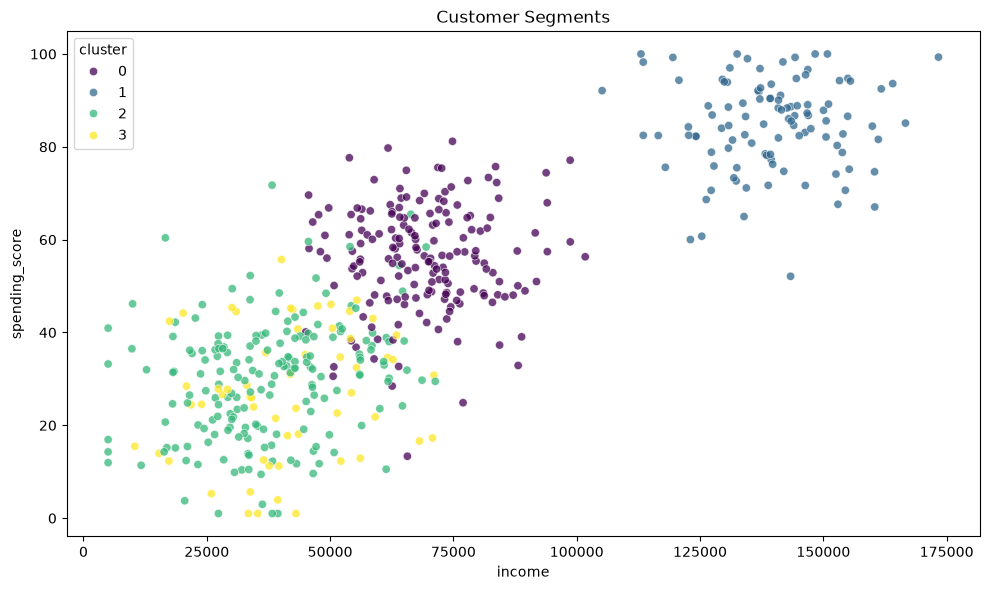

In [10]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="income",
    y="spending_score",
    hue="cluster",
    palette="viridis",
    alpha=0.75
)

plt.title("Customer Segments")
plt.tight_layout()
plt.show()
